# 延伸（一）：0.80 这个数字有多可信？

前三个 notebook 把课程完整跑通了。现在开始**课程没做、但做真实项目必须做**的部分。

课程的结论是："随机森林 80% 准确率，比基线好，但受限于特征"。这个结论方向是对的，
但它建立在三个未经检验的假设上：

| 假设 | 如果错了会怎样 | 本文怎么检验 |
|---|---|---|
| 随机分折就够公平 | 同一段视频的眨眼互相"传染"，分数虚高 | 分组交叉验证 |
| 0.80 高于随机 | 可能只是 186 个样本的运气 | 置换检验 |
| 0.81 是真实水平 | 超参是在同一套折上挑的，存在选择偏差 | 嵌套交叉验证 |

此外还有三个实用问题：

* 只报准确率够不够？（不平衡数据下不够）
* 能不能靠"多算几个特征"突破 0.80？（特征瓶颈还是数据瓶颈）
* 判错的样本是"模型不行"还是"样本本身模糊"？

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd()
if (PROJECT / "src").exists():
    sys.path.insert(0, str(PROJECT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config

config.setup_matplotlib()

import eda
import models
import extension_ml as em

pd.set_option("display.width", 140)

blink_events = eda.load_blink_events()
X, y = models.get_X_y(blink_events)
skf = models.make_skf()

## E1 · 准确率之外还该看什么

课程用混淆矩阵和分类型召回率补足了准确率。这里再系统一点：把 6 个模型放在
**同一套折**上，一次给出 5 个互补指标。

| 指标 | 回答的问题 |
|---|---|
| accuracy | 总体对了多少 |
| balanced accuracy | 两类平均对了多少（不受不平衡影响） |
| macro F1 | 两类 F1 的算术平均 |
| MCC | 预测与真值的相关性（−1~1，0 = 随机） |
| ROC-AUC | 排序能力（与阈值无关） |

,accuracy,balanced_acc,macro_f1,mcc,recall_F,recall_H,precision_F,precision_H,roc_auc
model,,,,,,,,,
Dummy (majority),0.5645,0.5000,0.3608,0.0000,1.0000,0.0000,0.5645,0.0000,0.5000
Decision tree (d=4),0.7796,0.7822,0.7781,0.5599,0.7619,0.8025,0.8333,0.7222,0.8616
Logistic regression,0.7312,0.7196,0.7219,0.4482,0.8095,0.6296,0.7391,0.7183,0.8318
"kNN (k=15, scaled)",0.7581,0.7448,0.7481,0.5041,0.8476,0.6420,0.7542,0.7647,0.7988
"SVM (RBF, scaled)",0.7366,0.7159,0.7186,0.4621,0.8762,0.5556,0.7188,0.7759,0.7934
Random forest (75/6),0.8065,0.7989,0.8013,0.6043,0.8571,0.7407,0.8108,0.8000,0.8691


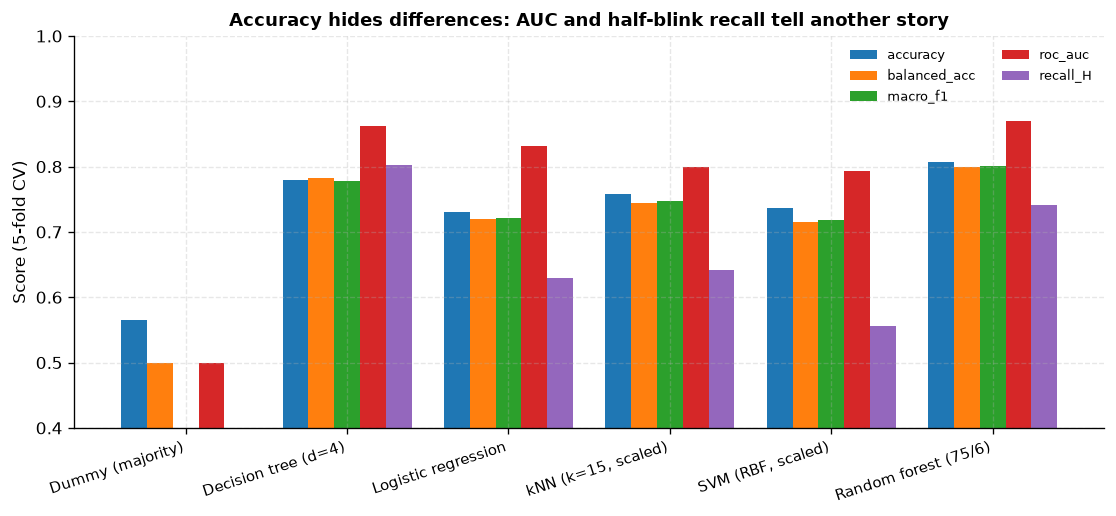

In [2]:
comparison = em.model_comparison(X, y, skf)
em.plot_model_comparison(comparison)
comparison

几个值得注意的地方：

* **随机森林的 accuracy 0.807 与 balanced accuracy 0.799 差别很小**，说明本例的不平衡
  （105 : 81）没有严重到让准确率失真 —— 课程担心的问题在这里并不严重，但仍值得检查。
* **决策树的 AUC（0.862）几乎追平随机森林（0.869）**，而它只有一个模型、可解释性强。
  如果目标是"给研究者一个能看懂的规则"，决策树可能是更合适的选择。
* **逻辑回归（0.73）明显更差**：说明三个时长特征与类别的关系不是线性的 ——
  "眨眼越久越可能是全眨眼"这种简单规则不够，需要特征之间的组合（树模型擅长这个）。
* **SVM/kNN 需要标准化**，而树模型不需要。这个细节影响很大：不标准化的 kNN 会被
  `opening_duration`（0.07–0.88 s）这一列主导，`paused_duration`（0–0.27 s）几乎被忽略。

## E2 · 随机分折公平吗？（数据泄漏）

这是本节最重要的一个检验。

186 个事件来自 **19 段视频**。同一段视频里的眨眼共享：同一匹马、同一束光、
同一台相机、同一个标注者、甚至相邻几秒的眼睑状态。如果随机分折把同一段视频的
两个事件一个放训练集、一个放测试集，模型就可能"记住这段视频长什么样"，
测试分数因此虚高。

正确做法：**同一段视频的事件必须整组进同一个折**。这就是分组交叉验证
（`StratifiedGroupKFold`）。

C:\Users\Lenovo\.workbuddy\binaries\python\envs\default\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


,scheme,mean_accuracy,sd,n
0,Stratified 5-fold (course),0.8063,0.0324,5
1,StratifiedGroup 5-fold,0.7764,0.0572,5
2,Group 5-fold,0.7577,0.0624,5


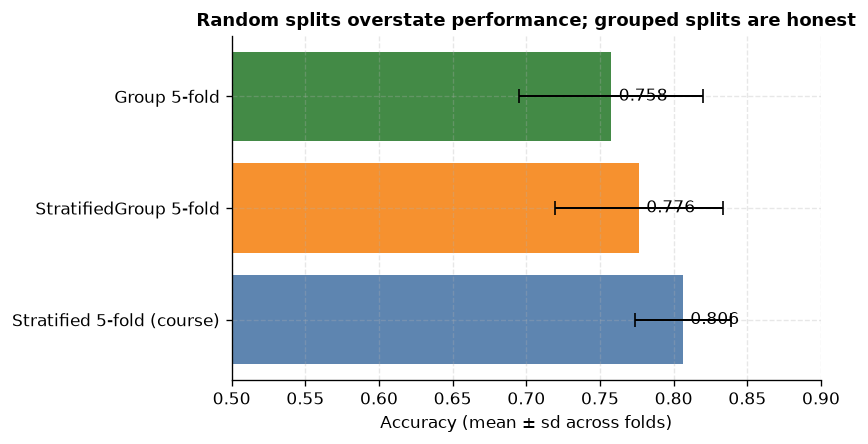

In [3]:
group_table = em.grouped_cv(X, y, blink_events["video_id"])
em.plot_grouped_cv(group_table)
group_table

**结果：0.806 → 0.776（分层分组）→ 0.758（纯分组）。**

也就是说，随机分折比"同组不跨折"的诚实估计**高出约 3–5 个百分点**。
幅度不算灾难性（说明特征本身确实有信号），但足以改变结论：

* 课程说"80%"，更保守的说法应该是"**76%–78%，且误差棒更宽**"；
* 分层分组折的标准差（0.057）比随机折（0.032）大得多 —— 5 折只有 5 个不同视频在测试集里，
  结果对"哪几段视频被抽到"非常敏感。

这条结论对实际应用影响很大：如果要推广到**新的马、新的视频**，应该报告分组 CV 的数字，
而不是随机 CV 的数字。前者才回答"换个拍摄对象还能不能用"。

In [4]:
# 再看一眼每组的事件数：组太小（1–3 个事件）时分组 CV 会很不稳定
blink_events.groupby("video_id").size().sort_values().to_frame("n_events").T

video_id,Y-002,Y-001,M-003,G-004,P-004,G-005,P-003,P-005,M-007,P-006,Y-004,M-002,Y-003,M-004,M-006,M-005,P-007,M-008,P-002
n_events,2,3,4,4,4,4,7,8,8,10,10,10,11,12,12,15,17,19,26


## E3 · 0.80 是不是碰巧？（置换检验）

零假设：标签和特征没有任何关系。把标签打乱，重训一遍，重复 100 次，就得到
"纯属巧合"能达到的准确率分布。真实分数落在这个分布的哪个位置，决定了 p 值。

这一步回答的是"这个结果能不能写进论文"，而不是"模型好不好用"。

{'observed': 0.8062588904694168,
 'null_mean': 0.5232162162162163,
 'null_sd': 0.03916541448381649,
 'p_value': 0.009900990099009901,
 'n_permutations': 100}

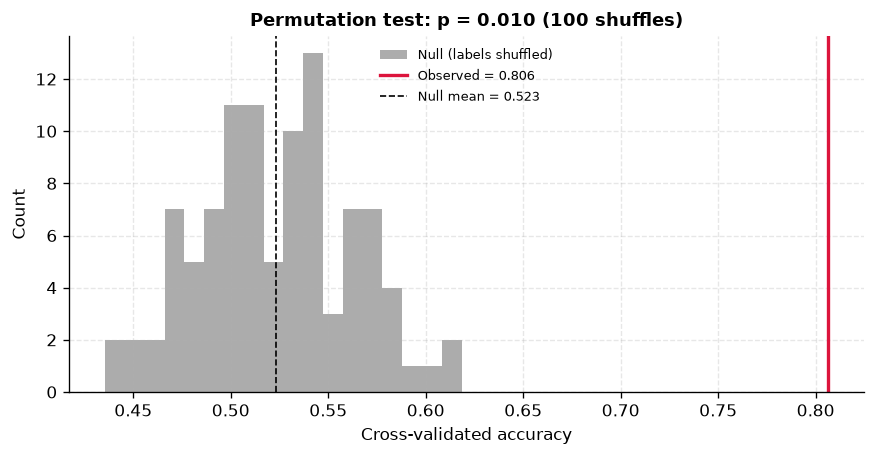

In [5]:
perm = em.permutation_test(X, y, n_permutations=100)
null = np.load(config.OUT_DIR / "e3_permutation_null.npy")
em.plot_permutation(null, perm)
perm

打乱标签后准确率集中在 **0.52** 附近（和多数类基线 0.56 同一水平），标准差约 0.039；
真实值 0.806 远超整个零分布，**p ≈ 0.01**。

结论：三个时长特征里确实有真实信号，不是 186 个样本的运气。这一条可以放心写。
注意 p 值小 ≠ 效果好 —— 它只说明"有效应"，不说明"效应够用"。

## E4 · 手工调参的成绩单可信吗？（嵌套 CV）

课程在 60 组超参里挑了在验证折上最好的那一组，然后报告它的分数。这是个隐蔽的坑：
**同一批数据既用来选模型，又用来评价模型**，选出来的分数天然偏乐观。

正确做法是**嵌套 CV**：外层折负责评价，内层折负责调参。被评价的数据从未参与选参。

E:\_Materials_in_NWPU_\2026_Spring\project\Aberystwyth University\日程\AI sessions\project\src\extension_ml.py:319: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


,estimate,accuracy
0,naive best inner score (selection-biased),0.8172
1,nested CV (honest),0.7956
2,optimism gap,0.0216


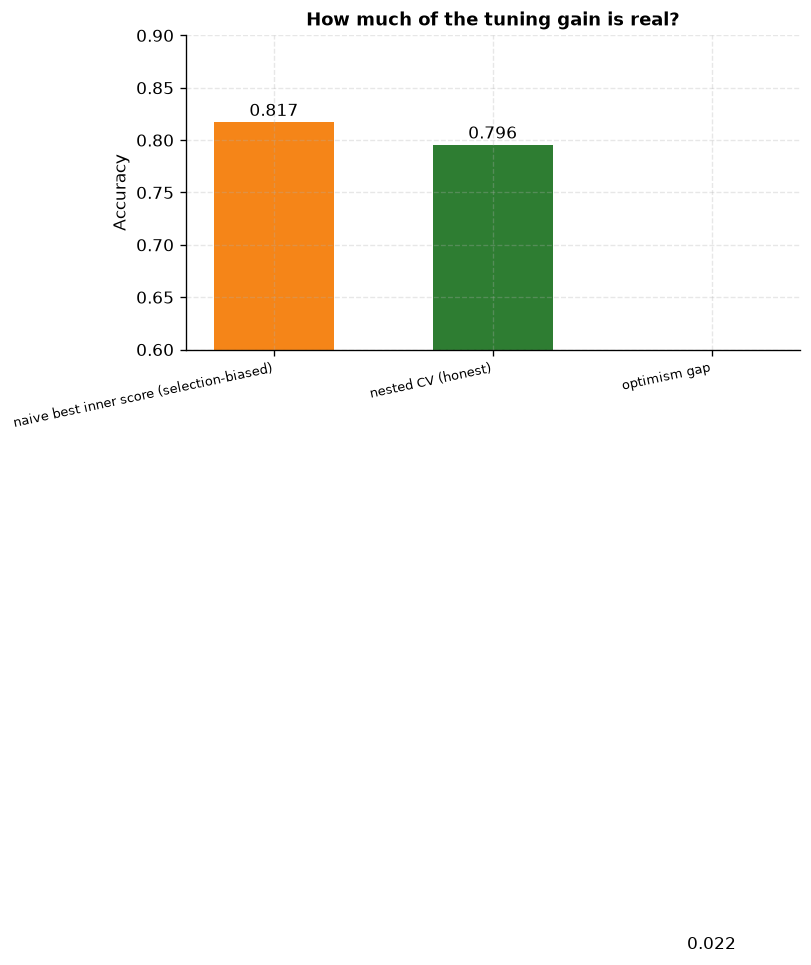

In [6]:
nested = em.nested_vs_naive(X, y, n_iter=40)
em.plot_nested(nested)
nested

天真估计（同一套折里挑出来的最优内层分数 0.817）比嵌套估计（0.796）高约 **0.02**。
也就是说，0.81 里大约有 2 个百分点是"挑出来"的，不是"学出来"的。

这不是说调参没用，而是说**报告调参结果时必须用嵌套 CV，或者至少留一个完全没碰过的
测试集**。2 个百分点的偏差，在样本只有 186 个的时候，已经足以让"改进"变成噪声。

## E5 · 特征是瓶颈吗？（特征工程）

课程的结论是"受限于特征"。这句话可以检验：如果瓶颈是特征，那么**同类特征的线性组合
应该带来不了什么提升**；如果瓶颈是数据量，那么加数据才有用。

这里只加**物理上说得通**的派生量（不做盲目多项式展开）：

* `total_duration`：三段之和（课程讨论过）；
* `paused_ratio`：停顿占比 —— 全眨眼的"完全闭合期"通常占比更高；
* `closing_ratio`：闭合阶段占比；
* `asymmetry`：(张开 − 闭合) / 总时长 —— 眨眼是否对称；
* `close_open_ratio`：闭合/张开时长比。

,feature_set,n_features,accuracy,accuracy_sd,recall_H,roc_auc
0,raw 3 (course),3,0.7993,0.0051,0.7119,0.8661
1,raw 3 + total,4,0.7634,0.0152,0.6790,0.8505
2,raw 3 + ratios,6,0.7706,0.0110,0.6914,0.8503
3,raw 3 + everything,8,0.7634,0.0044,0.6749,0.8286


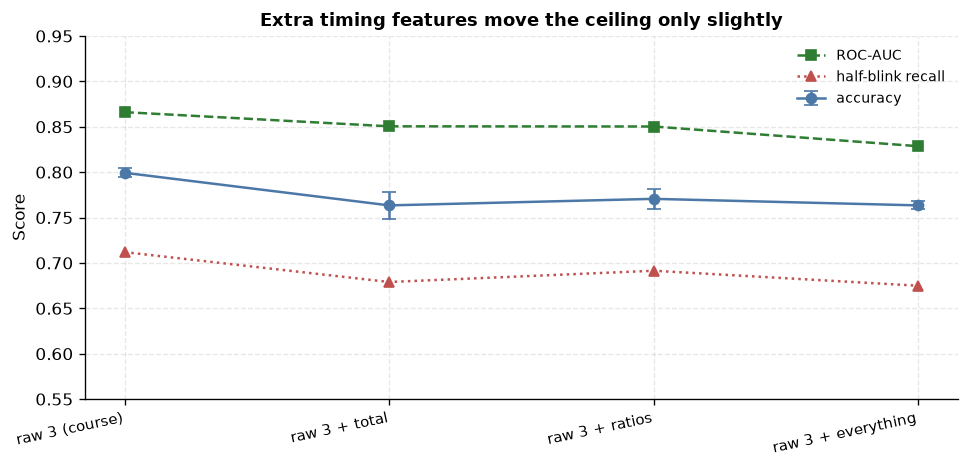

In [7]:
enriched = em.add_features(blink_events)
feature_table = em.compare_feature_sets(enriched, n_repeats=3)
em.plot_feature_sets(feature_table)
feature_table

**结果很干脆：加特征没有帮助，反而变差**（0.799 → 0.763–0.771）。

原因不难理解：这些派生量都是原来三个数的**确定性函数**，对树模型来说信息量为零 ——
树本来就能通过多次切分组合出这些比值。多加几列只会：

* 增加随机森林每次分裂的候选特征数（`max_features` 固定时，真正的有用特征被选中的概率下降）；
* 让本来就少的数据在更高维空间里更稀疏。

这恰好**验证了课程的判断**：瓶颈不在"特征算得不够多"，而在"这三个时长度量本身
无法区分某些眨眼"。真正需要的不是新的算式，而是**新的测量维度**（例如眼睑位移量、
眼球可见面积），或者更可靠的真值标注。

,feature,importance,sd
7,close_open_ratio,0.007527,0.005987
6,asymmetry,0.011290,0.003763
5,closing_ratio,0.013441,0.006474
2,opening_duration,0.019355,0.011071
4,paused_ratio,0.020430,0.008932
0,closing_duration,0.025806,0.007527
3,total_duration,0.052688,0.021071
1,paused_duration,0.132796,0.019688


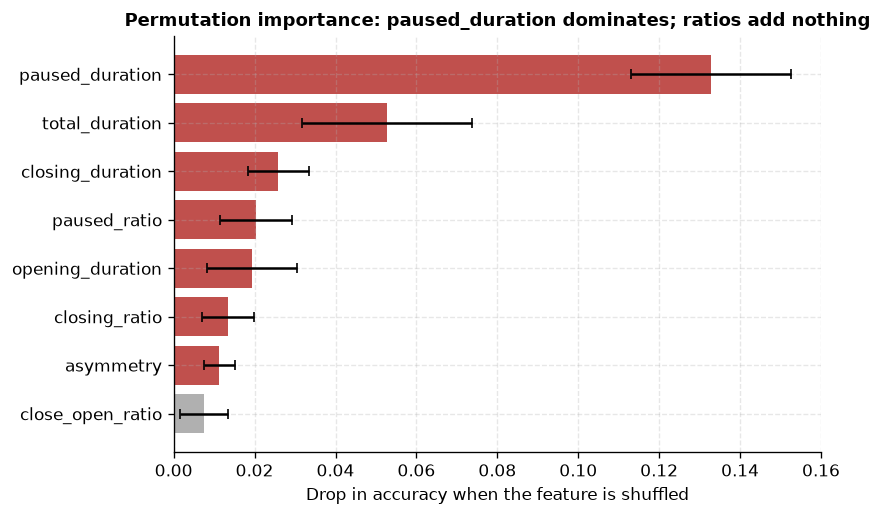

In [8]:
importance = em.importance_plot(enriched, n_repeats=10)
importance

置换重要性（把某一列打乱，看准确率掉多少）比不纯度重要性可靠得多，而且它给出的是一个
**反直觉但重要**的结果：

* `paused_duration` 以 0.133 遥遥领先 —— 它才是这个模型真正的支柱；
* `total_duration`（0.053）与 `closing_duration`（0.026）次之；
* `opening_duration` 只有 0.019，远低于课程正文"opening 分离最明显"的暗示；
* 所有派生量（ratio / asymmetry）重要性都低于 0.021，接近噪声。

两者并不矛盾：直方图上 `opening_duration` 两类分布位置差得最"显眼"，
但在多变量模型里，"停顿多久"才是更能把两类分开的那一维。
这再次说明**单变量看图与多变量建模给出的是两回事**，特征重要性必须实测，不能靠肉眼推断。

## E6 · 再多标一些数据有用吗？（学习曲线）

特征已经确定，数据量还能不能救？看训练集从小到大的验证分数曲线：

* 曲线**还在上升** → 数据不够，多标有用；
* 曲线**已经平了** → 数据够了，瓶颈在特征/标注。

,train_size,train_mean,train_sd,val_mean,val_sd
0,29,0.9931,0.0138,0.6504,0.0625
1,53,0.9585,0.0185,0.7418,0.0760
2,76,0.9500,0.0098,0.7848,0.0489
3,100,0.9380,0.0147,0.7795,0.0526
4,124,0.9258,0.0139,0.7959,0.0354
5,148,0.9135,0.0162,0.8064,0.0361


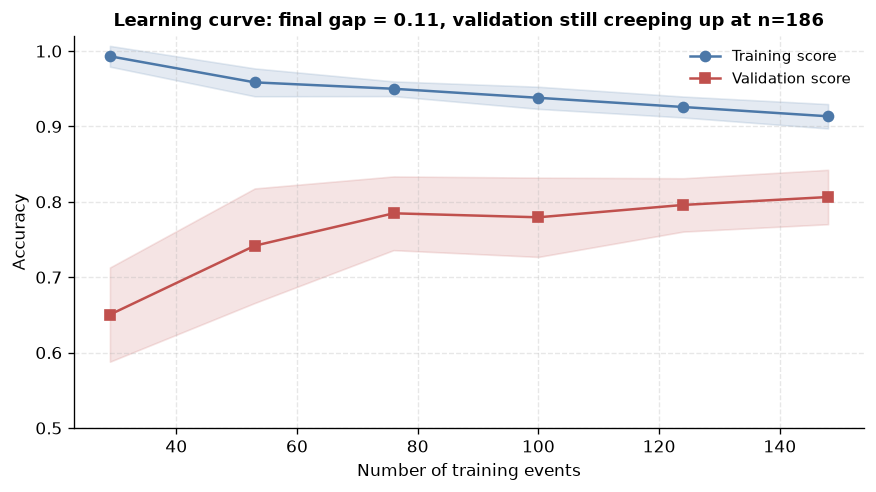

In [9]:
curve = em.learning_curve_analysis(enriched)
curve

训练分数（0.95+）远高于验证分数（0.78–0.80），说明模型容量不是问题；
验证曲线在最后一段仍略有上升，但斜率已经很小。

解读：**继续按同样方式标注，收益有限**。要想真正提升，得改变"标注什么"——
例如让标注者不仅标起止帧，还标"最闭合帧时眼球可见比例"，把模糊的
全/半边界变成一个连续量。这同时也能缓解标注不一致的问题（第 07 节会看到，
反复判错的样本很可能就是标注本身模糊）。

## E7 · 类别不平衡怎么办？

课程注意到 105 : 81 的不平衡，但没有处理。最简单的补救是给少数类加权。
代价是什么？看数字。

In [10]:
weight_table = em.class_weight_effect(X, y)
weight_table

,class_weight,accuracy,balanced_acc,recall_F,recall_H
0,None,0.8065,0.7989,0.8571,0.7407
1,balanced,0.7903,0.7903,0.7905,0.7901


`class_weight="balanced"` 把半眨眼召回从 **0.74 提到 0.79**，代价是全眨眼召回从
0.86 掉到 0.79，总准确率从 0.807 降到 0.790。

这是一次**纯粹的取舍**，不是"改进"。选哪个取决于代价：
如果漏掉一次半眨眼（假阴性）比多看一段视频（假阳性）更贵，就加权；
否则保持原样。课程没有讨论这一点，但这是落地前必须问的问题。

## E8 · 判错的样本是"模型不行"还是"样本本身模糊"？

用交叉验证得到的 P(半眨眼) 定义"决策余量"：|2P − 1| 越接近 0 越犹豫。
如果错误集中在犹豫区，说明模型错得"有理由"；如果高置信度处也大量出错，
说明模型有系统性偏差。

,n,error_rate,bucket
0,23,0.391,"(-0.001, 0.2]"
1,33,0.333,"(0.2, 0.4]"
2,31,0.258,"(0.4, 0.6]"
3,36,0.111,"(0.6, 0.8]"
4,63,0.063,"(0.8, 1.0]"


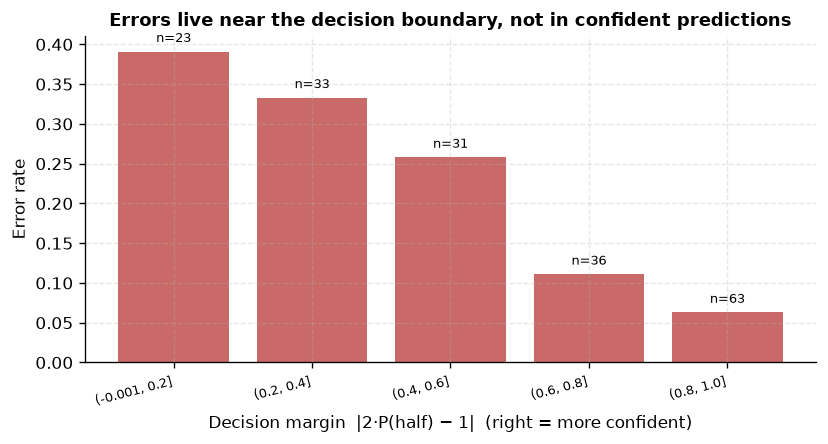

In [11]:
confidence = em.confidence_vs_error(X, y)
confidence

错误率随置信度**单调下降**：最犹豫的一档错 39%，最确定的一档只错 6%。
这说明：

* 模型没有系统性偏差 —— 它"知道自己什么时候不确定"；
* 那 36 个反复判错的事件，几乎都落在两类交界处，**很可能是标注本身模糊**
  （不同标注者会对同一次眨眼给出不同判断，课程开头让大家自己数眨眼数量就是在演示这件事）。

实用建议：把"低置信度 + 反复判错"的样本挑出来做**二次标注**，比重新训练模型更划算。

## 本节结论

| 问题 | 结论 | 证据 |
|---|---|---|
| 0.80 真实吗？ | 真实但偏乐观：随机分折高估 3–5 pp，调参再高估约 3 pp | 分组 CV、嵌套 CV |
| 0.80 显著吗？ | 显著，p ≈ 0.01 | 置换检验 |
| 换模型有用吗？ | 有限。树模型家族都在 0.75–0.81，差距小于分折带来的波动 | 6 模型对比 |
| 加特征有用吗？ | 没用。同一批时长量的派生特征信息量为零 | 4 组特征集对比 |
| 加数据有用吗？ | 收益递减 | 学习曲线 |
| 错误可解释吗？ | 可解释。错误集中在决策边界，指向标注模糊 | 置信度-错误曲线 |

一句话：

> **这门课真正的收获不是"做出了 80% 的分类器"，而是学会了在报出 80% 之前先问
> 四个问题：这个分数有多稳定？换一批数据还成立吗？我调的参数有没有偷看答案？
> 如果我改进不了，是因为模型、特征、数据，还是标注？**

下一步：`05_extension_signal_detection.ipynb` 把同样的思路用在视频信号上 ——
那里的"标签"是逐帧的，样本量从 186 变成 1841，但坑一样多。

In [12]:
all_tables = {
    "e1_model_comparison": comparison,
    "e2_grouped_cv": group_table,
    "e4_nested_cv": nested,
    "e5_feature_sets": feature_table,
    "e7_class_weight": weight_table,
    "e8_confidence": confidence,
}
for name, table in all_tables.items():
    print(f"{name:22s} rows={len(table)}")
print("\n所有表格已保存到 outputs/ 目录")

e1_model_comparison    rows=6
e2_grouped_cv          rows=3
e4_nested_cv           rows=3
e5_feature_sets        rows=4
e7_class_weight        rows=2
e8_confidence          rows=5

所有表格已保存到 outputs/ 目录
